# LOAD DATA

In [1]:
import pandas as pd
import numpy as np

# Membaca data yang sudah kamu simpan sebelumnya
df = pd.read_csv('BBCA_historical_data.csv', index_col='Date', parse_dates=True)

# Memastikan datanya berurutan dari tanggal terlama ke terbaru
df.sort_index(inplace=True)

print("Data mentah berhasil dimuat. Total baris:", len(df))

Data mentah berhasil dimuat. Total baris: 1586


# FEATURE MAKING

In [2]:
# 1. Fitur Perubahan Harga & Volume Harian
df['Return_1d'] = df['Close'].pct_change() # Persentase naik/turun harga hari ini
df['Vol_Change'] = df['Volume'].pct_change() # Lonjakan atau penurunan volume transaksi

# 2. Fitur Tren: MACD (Moving Average Convergence Divergence)
# Menggunakan Exponential Moving Average (EMA) yang lebih responsif dari SMA
ema_12 = df['Close'].ewm(span=12, adjust=False).mean()
ema_26 = df['Close'].ewm(span=26, adjust=False).mean()
df['MACD'] = ema_12 - ema_26

# 3. Fitur Momentum: RSI (Relative Strength Index) 14-hari
# Menghitung seberapa jenuh kondisi beli (overbought) atau jual (oversold)
delta = df['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()

# Menghindari pembagian dengan angka nol
loss = loss.replace(0, 0.0001) 
rs = gain / loss
df['RSI_14'] = 100 - (100 / (1 + rs))

print("Fitur indikator teknikal selesai diracik!")

Fitur indikator teknikal selesai diracik!


# VARIABEL TARGET

In [3]:
# Logika Target: Jika harga penutupan BESOK (shift -1) lebih besar dari HARI INI, beri nilai 1 (Naik).
# Jika sama atau turun, beri nilai 0 (Turun/Datar).
df['Target'] = np.where(df['Close'].shift(-1) > df['Close'], 1, 0)

# Saat menghitung RSI atau memajukan data (shift), akan ada baris yang kosong (NaN).
# Mesin Learning sangat benci data kosong, jadi kita harus membuangnya.
df.dropna(inplace=True)

print("Kunci jawaban (Target) berhasil dibuat dan data bersih!")

Kunci jawaban (Target) berhasil dibuat dan data bersih!


# INSPEKSI FITUR

In [4]:
# Menampilkan fitur (Variabel X) dan Target (Variabel Y)
kolom_penting = ['Close', 'Return_1d', 'Vol_Change', 'MACD', 'RSI_14', 'Target']
df[kolom_penting].tail(10)

,Close,Return_1d,Vol_Change,MACD,RSI_14,Target
Date,,,,,,
2026-07-20 00:00:00+07:00,6475.0,0.000000,-0.052075,112.336996,82.456140,1
2026-07-21 00:00:00+07:00,6525.0,0.007722,-0.510151,128.329759,82.456140,0
2026-07-22 00:00:00+07:00,6500.0,-0.003831,-0.231992,137.402952,78.000000,0
2026-07-23 00:00:00+07:00,6275.0,-0.034615,0.845605,124.997016,59.183673,0
2026-07-24 00:00:00+07:00,6275.0,0.000000,-0.075392,113.852798,56.521739,1
2026-07-27 00:00:00+07:00,6300.0,0.003984,-0.346272,105.818407,50.000000,0
2026-07-28 00:00:00+07:00,6225.0,-0.011905,-0.017757,92.334842,52.631579,1
2026-07-29 00:00:00+07:00,6275.0,0.008032,-0.004399,84.707151,53.846154,1
2026-07-30 00:00:00+07:00,6450.0,0.027888,0.247456,91.725830,62.222222,0


# DATA CLEANING

In [7]:
import numpy as np

# 1. Mengubah semua nilai tak terhingga (infinity) menjadi nilai kosong (NaN)
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# 2. Menyapu bersih (menghapus) baris yang memiliki nilai kosong tersebut
df.dropna(inplace=True)

print("Pembersihan selesai! Angka Infinity sudah dihapus dari data.")

Pembersihan selesai! Angka Infinity sudah dihapus dari data.


# SPLITTING DATA (TRAIN-TEST)

In [10]:
# Menentukan Variabel X (Fitur/Petunjuk) dan Variabel Y (Target/Jawaban)
fitur = ['Return_1d', 'Vol_Change', 'MACD', 'RSI_14']
X = df[fitur]
y = df['Target']

# Kita potong datanya: 
# Tahun 2020 s.d. Akhir 2024 untuk Belajar (Training)
# Tahun 2025 s.d. 2026 untuk Ujian (Testing)
batas_waktu = '2025-01-01'

X_train = X[X.index < batas_waktu]
X_test = X[X.index >= batas_waktu]

y_train = y[y.index < batas_waktu]
y_test = y[y.index >= batas_waktu]

print(f"Jumlah data belajar: {len(X_train)} hari")
print(f"Jumlah data ujian: {len(X_test)} hari")

Jumlah data belajar: 1196 hari
Jumlah data ujian: 371 hari


# TRAINING PROCESS

In [11]:
from sklearn.ensemble import RandomForestClassifier

# Membuat 'otak' kosong Random Forest
# n_estimators=100 artinya kita menyuruh mesin membuat 100 pohon keputusan
# random_state=42 hanya agar hasilnya konsisten jika dijalankan berulang-ulang
model_rf = RandomForestClassifier(n_estimators=100, min_samples_split=50, random_state=42)

# Memasukkan data ke dalam 'otak' agar mesin mulai belajar mencari pola
model_rf.fit(X_train, y_train)

print("Proses training mesin selesai!")

Proses training mesin selesai!


# TEST AND EVALUTAION

In [12]:
from sklearn.metrics import precision_score, accuracy_score

# Menyuruh mesin menebak arah saham di masa ujian (2025-2026)
prediksi = model_rf.predict(X_test)

# Menghitung nilai rapor
akurasi = accuracy_score(y_test, prediksi)
presisi = precision_score(y_test, prediksi)

print(f"Skor Akurasi Umum : {akurasi * 100:.2f}%")
print(f"Skor Presisi (Beli): {presisi * 100:.2f}%")

Skor Akurasi Umum : 54.72%
Skor Presisi (Beli): 44.97%


# SIMULASI KEUNTUNGAN & SHARPE RATIO

In [13]:
import numpy as np

# 1. Menyiapkan tabel khusus untuk masa ujian (2025-2026)
df_test = df[df.index >= batas_waktu].copy()

# Memasukkan hasil tebakan mesin ke dalam tabel
df_test['Prediksi_Model'] = prediksi

# 2. Menghitung Keuntungan Strategi
# Sama seperti aturan sebelumnya: Kita baru bisa beli hari ini jika mesin menyuruh beli KEMARIN (shift 1)
df_test['Strategy_Return'] = df_test['Return_1d'] * df_test['Prediksi_Model'].shift(1)

# Buang baris pertama yang kosong karena efek pergeseran (shift)
df_test.dropna(inplace=True) 

# 3. Menghitung Pertumbuhan Uang (Modal Awal Rp 10 Juta)
modal_awal = 10000000
df_test['Total_Uang_Pasif'] = modal_awal * (1 + df_test['Return_1d']).cumprod()
df_test['Total_Uang_Strategi'] = modal_awal * (1 + df_test['Strategy_Return']).cumprod()

# 4. Menghitung Metrik Sharpe Ratio
# Asumsi keuntungan tanpa risiko (Risk-Free Rate) adalah 0% agar simpel
# Angka 252 adalah standar jumlah hari aktif bursa saham dalam satu tahun
rata_rata_untung_harian = df_test['Strategy_Return'].mean()
volatilitas_harian = df_test['Strategy_Return'].std()

# Rumus Matematis Sharpe Ratio (Disetahunkan / Annualized)
sharpe_ratio = (rata_rata_untung_harian - 0) / volatilitas_harian * np.sqrt(252)

# 5. Mencetak Hasil Akhir
uang_akhir_pasif = df_test['Total_Uang_Pasif'].iloc[-1]
uang_akhir_strategi = df_test['Total_Uang_Strategi'].iloc[-1]

print("=== HASIL UJIAN MODEL MACHINE LEARNING ===")
print(f"Total Uang (Beli & Diam) : Rp {uang_akhir_pasif:,.0f}")
print(f"Total Uang (Model ML)    : Rp {uang_akhir_strategi:,.0f}")
print(f"Skor Sharpe Ratio        : {sharpe_ratio:.2f}")

=== HASIL UJIAN MODEL MACHINE LEARNING ===
Total Uang (Beli & Diam) : Rp 7,223,414
Total Uang (Model ML)    : Rp 8,913,015
Skor Sharpe Ratio        : -0.26


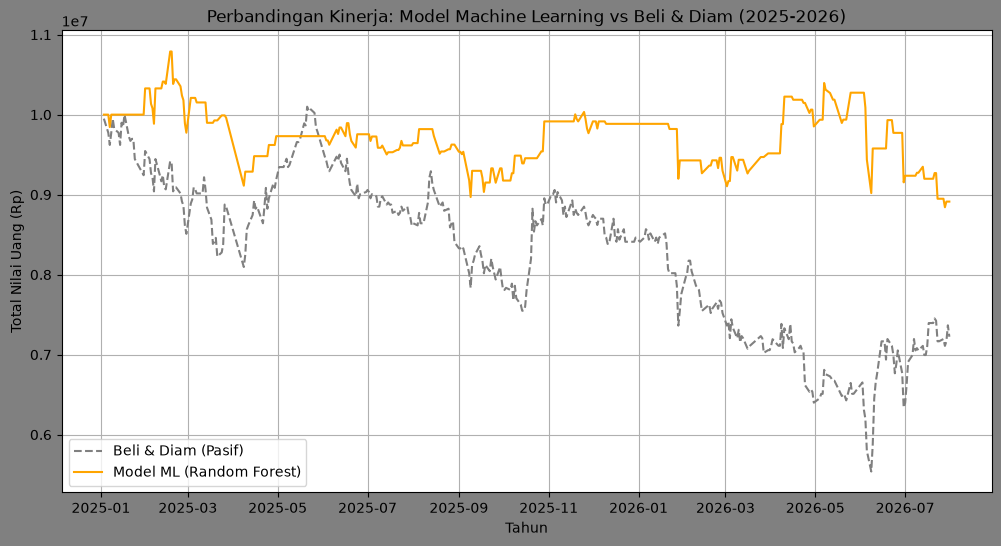

In [17]:
import matplotlib.pyplot as plt

# Membuat kanvas gambar berukuran 12x6
plt.figure(figsize=(12, 6), facecolor='gray')

# Menggambar garis pertumbuhan uang pasif (Abu-abu putus-putus)
plt.plot(df_test.index, df_test['Total_Uang_Pasif'], label='Beli & Diam (Pasif)', color='gray', linestyle='--')

# Menggambar garis pertumbuhan uang dari Model ML (Oranye solid)
plt.plot(df_test.index, df_test['Total_Uang_Strategi'], label='Model ML (Random Forest)', color='orange')

# Menambahkan judul dan keterangan
plt.title('Perbandingan Kinerja: Model Machine Learning vs Beli & Diam (2025-2026)')
plt.xlabel('Tahun')
plt.ylabel('Total Nilai Uang (Rp)')

# Menampilkan legenda dan grid
plt.legend()
plt.grid(True)


# Menampilkan grafik
plt.show()